# Exploratory Data Analysis

Exploratory analysis of the Xente transaction dataset to guide feature engineering and proxy target creation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make project src/ importable from notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_processing import (
    CATEGORICAL_FEATURE_COLS,
    HighRiskLabelGenerator,
    NUMERIC_FEATURE_COLS,
    RFMTransformer,
    aggregate_to_customer_level,
    load_raw_data,
)

sns.set_style("whitegrid")
%matplotlib inline

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "data.csv"
df = load_raw_data(str(DATA_PATH))
df.head()

,TransactionId,BatchId,AccountId,SubscriptionId,CustomerId,CurrencyCode,CountryCode,ProviderId,ProductId,ProductCategory,ChannelId,Amount,Value,TransactionStartTime,PricingStrategy,FraudResult
0,TransactionId_76871,BatchId_36123,AccountId_3957,SubscriptionId_887,CustomerId_4406,UGX,256,ProviderId_6,ProductId_10,airtime,ChannelId_3,1000.0,1000,2018-11-15T02:18:49Z,2,0
1,TransactionId_73770,BatchId_15642,AccountId_4841,SubscriptionId_3829,CustomerId_4406,UGX,256,ProviderId_4,ProductId_6,financial_services,ChannelId_2,-20.0,20,2018-11-15T02:19:08Z,2,0
2,TransactionId_26203,BatchId_53941,AccountId_4229,SubscriptionId_222,CustomerId_4683,UGX,256,ProviderId_6,ProductId_1,airtime,ChannelId_3,500.0,500,2018-11-15T02:44:21Z,2,0
3,TransactionId_380,BatchId_102363,AccountId_648,SubscriptionId_2185,CustomerId_988,UGX,256,ProviderId_1,ProductId_21,utility_bill,ChannelId_3,20000.0,21800,2018-11-15T03:32:55Z,2,0
4,TransactionId_28195,BatchId_38780,AccountId_4841,SubscriptionId_3829,CustomerId_988,UGX,256,ProviderId_4,ProductId_6,financial_services,ChannelId_2,-644.0,644,2018-11-15T03:34:21Z,2,0


## 1. Overview of the Data

In [2]:
print(f'Rows: {df.shape[0]:,}, Columns: {df.shape[1]}')
print('\nData types:')
print(df.dtypes)
df.info()

Rows: 95,662, Columns: 16

Data types:
TransactionId            object
BatchId                  object
AccountId                object
SubscriptionId           object
CustomerId               object
CurrencyCode             object
CountryCode               int64
ProviderId               object
ProductId                object
ProductCategory          object
ChannelId                object
Amount                  float64
Value                     int64
TransactionStartTime     object
PricingStrategy           int64
FraudResult               int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95662 entries, 0 to 95661
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   TransactionId         95662 non-null  object 
 1   BatchId               95662 non-null  object 
 2   AccountId             95662 non-null  object 
 3   SubscriptionId        95662 non-null  object 
 4   CustomerId     

## 2. Summary Statistics

In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TransactionId,95662,95662,TransactionId_35670,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BatchId,95662,94809,BatchId_67019,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccountId,95662,3633,AccountId_4841,30893,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubscriptionId,95662,3627,SubscriptionId_3829,32630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CustomerId,95662,3742,CustomerId_7343,4091,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CurrencyCode,95662,1,UGX,95662,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CountryCode,95662.0,NaN,NaN,NaN,256.0,0.0,256.0,256.0,256.0,256.0,256.0
ProviderId,95662,6,ProviderId_4,38189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProductId,95662,23,ProductId_6,32635,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProductCategory,95662,9,financial_services,45405,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Distribution of Numerical Features

Numeric columns: ['CountryCode', 'Amount', 'Value', 'PricingStrategy', 'FraudResult']
Zero-variance (drop these): ['CountryCode']

Skewness:
Amount    51.10
Value     51.29
dtype: float64


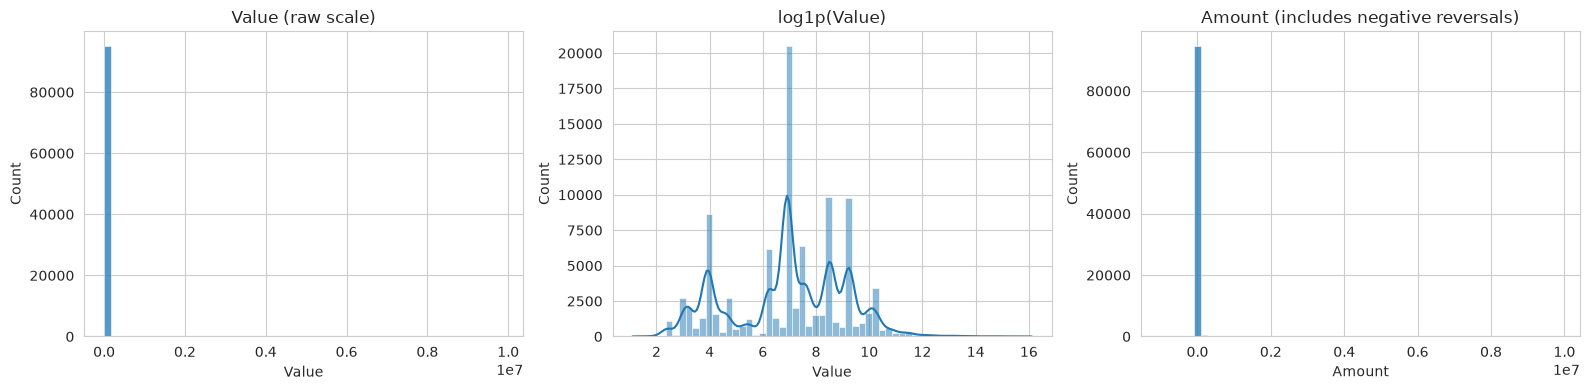

Transactions with negative Amount (refunds/reversals): 39.9%


In [4]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
constant_cols = [c for c in num_cols if df[c].nunique() <= 1]
print('Numeric columns:', num_cols)
print('Zero-variance (drop these):', constant_cols)
print('\nSkewness:')
print(df[['Amount', 'Value']].skew().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['Value'], bins=60, kde=False, ax=axes[0])
axes[0].set_title('Value (raw scale)')

# Raw scale is unreadable at skew ~51, so view the log1p transform as well.
sns.histplot(np.log1p(df['Value']), bins=60, kde=True, ax=axes[1])
axes[1].set_title('log1p(Value)')

sns.histplot(df['Amount'], bins=60, kde=False, ax=axes[2])
axes[2].set_title('Amount (includes negative reversals)')
plt.tight_layout()
plt.show()

negative_share = (df['Amount'] < 0).mean()
print(f'Transactions with negative Amount (refunds/reversals): {negative_share:.1%}')

## 4. Distribution of Categorical Features

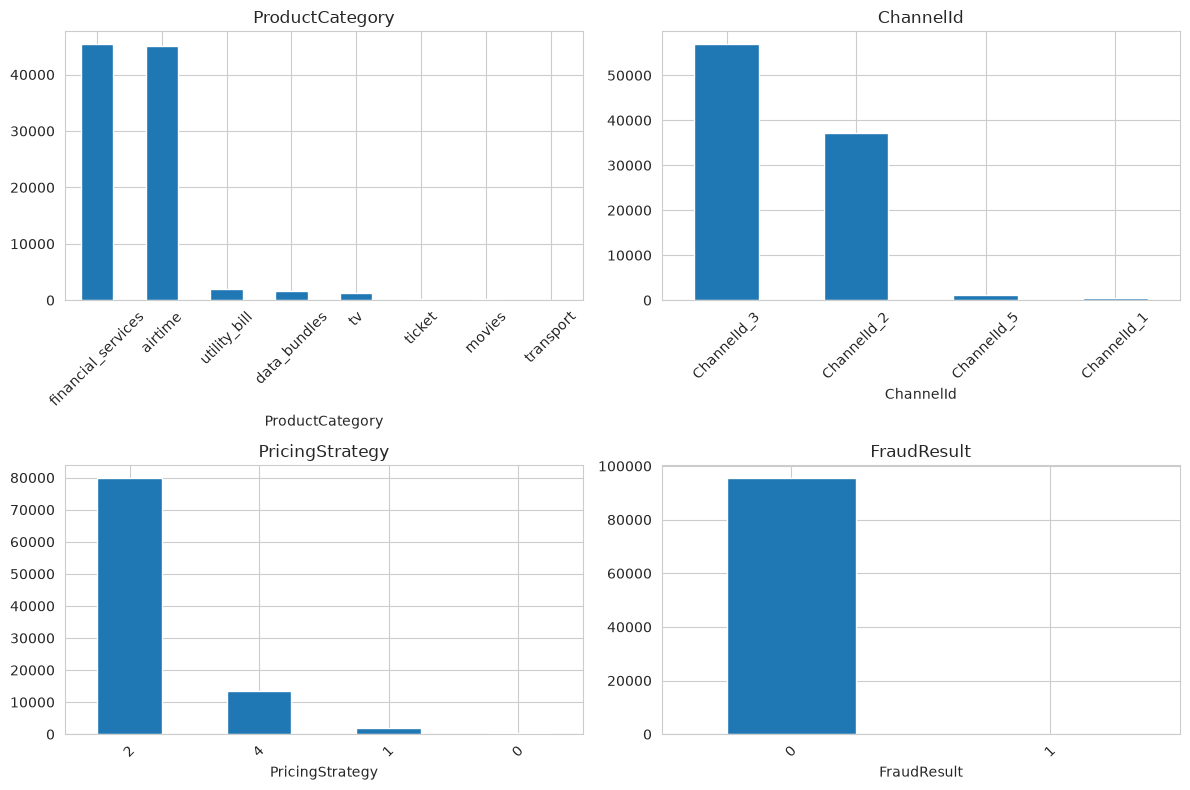

In [5]:
cat_cols = ['ProductCategory', 'ChannelId', 'PricingStrategy', 'FraudResult']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cat_cols):
    df[col].value_counts().head(8).plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## 5. Correlation Analysis

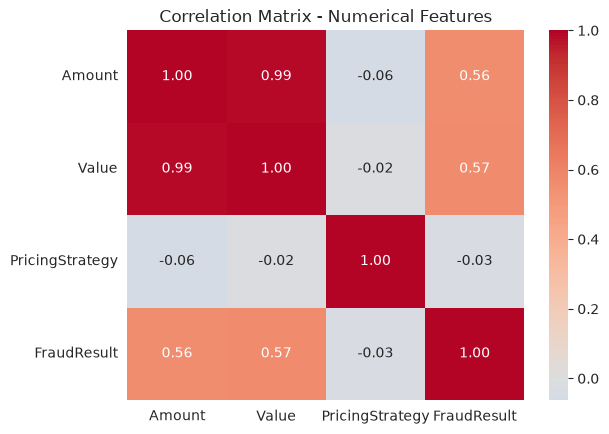

Amount vs Value correlation: 0.990
Value is the absolute magnitude of Amount, so the pair is near-collinear;
the RFM aggregates are built on Value to avoid double counting.


In [6]:
# Exclude zero-variance columns, whose correlation is undefined.
corr_cols = [c for c in df.select_dtypes(include=np.number).columns if df[c].nunique() > 1]
corr = df[corr_cols].corr()

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix - Numerical Features')
plt.show()

print(f"Amount vs Value correlation: {df['Amount'].corr(df['Value']):.3f}")
print('Value is the absolute magnitude of Amount, so the pair is near-collinear;')
print('the RFM aggregates are built on Value to avoid double counting.')

## 6. Missing Values

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)
missing[missing > 0] if missing.sum() else 'No missing values detected.'

'No missing values detected.'

## 7. Outlier Detection

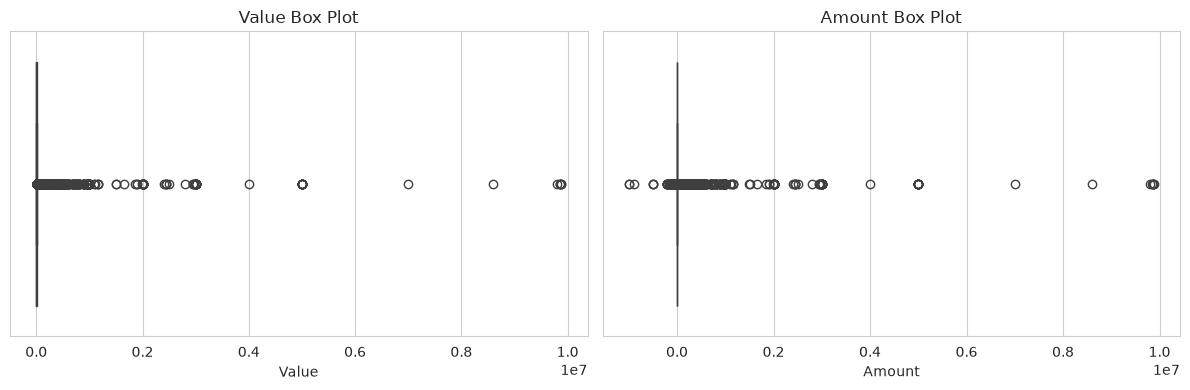

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['Value'], ax=axes[0])
axes[0].set_title('Value Box Plot')
sns.boxplot(x=df['Amount'], ax=axes[1])
axes[1].set_title('Amount Box Plot')
plt.tight_layout()
plt.show()

## 8. Feature Engineering Preview (from `src`)

Use production transformers from `src/data_processing.py` to validate RFM features and the proxy target before running the full pipeline.

In [9]:
snapshot_date = pd.to_datetime(df["TransactionStartTime"]).max()

rfm_transformer = RFMTransformer(snapshot_date=snapshot_date)
rfm_df = rfm_transformer.transform(df.copy())

labeler = HighRiskLabelGenerator(n_clusters=3, random_state=42)
labeled_df = labeler.fit_transform(rfm_df)
customer_df = aggregate_to_customer_level(labeled_df)

print("Engineered feature columns:", NUMERIC_FEATURE_COLS + CATEGORICAL_FEATURE_COLS)
print(f"Customers: {customer_df['CustomerId'].nunique():,}")
print(f"High-risk rate: {customer_df['is_high_risk'].mean():.2%}")
customer_df.head()

Engineered feature columns: ['Recency', 'Frequency', 'MonetarySum', 'MonetaryMean', 'MonetaryStd', 'TransactionHour', 'TransactionDay', 'TransactionMonth', 'ProductCategory', 'ChannelId', 'PricingStrategy']
Customers: 3,742
High-risk rate: 38.11%


,CustomerId,Recency,Frequency,MonetarySum,MonetaryMean,MonetaryStd,TransactionHour,TransactionDay,TransactionMonth,ProductCategory,ChannelId,PricingStrategy,is_high_risk
0,CustomerId_1,83,1,10000,10000.000000,0.000000,16.000000,21.000000,11.000000,airtime,ChannelId_2,4,1
1,CustomerId_10,83,1,10000,10000.000000,0.000000,16.000000,21.000000,11.000000,airtime,ChannelId_2,4,1
2,CustomerId_1001,89,5,30400,6080.000000,4100.243895,7.800000,16.000000,11.000000,financial_services,ChannelId_3,2,1
3,CustomerId_1002,25,11,4775,434.090909,518.805446,13.454545,14.727273,8.636364,financial_services,ChannelId_2,2,0
4,CustomerId_1003,11,6,32000,5333.333333,3945.461528,14.333333,1.000000,2.000000,airtime,ChannelId_3,2,0


### Which cluster is the high-risk segment?

The proxy label is only defensible if the chosen cluster is genuinely the least engaged one. The table below profiles each K-Means cluster so the choice can be audited.

In [10]:
cluster_rfm = labeled_df.groupby("CustomerId")[["Recency", "Frequency", "MonetarySum"]].first()
cluster_rfm = cluster_rfm.join(
    labeler.customer_labels_.set_index("CustomerId")["cluster"]
)

profile = cluster_rfm.groupby("cluster").agg(
    customers=("Recency", "size"),
    avg_recency_days=("Recency", "mean"),
    avg_frequency=("Frequency", "mean"),
    avg_monetary=("MonetarySum", "mean"),
)
profile["share"] = profile["customers"] / profile["customers"].sum()

print(f"Cluster flagged as high risk: {labeler.high_risk_cluster_}")
profile.round(2)

Cluster flagged as high risk: 0


,customers,avg_recency_days,avg_frequency,avg_monetary,share
cluster,,,,,
0,1426,60.88,7.72,89737.93,0.38
1,2312,11.72,34.70,224756.50,0.62
2,4,22.25,1104.50,74876587.00,0.00


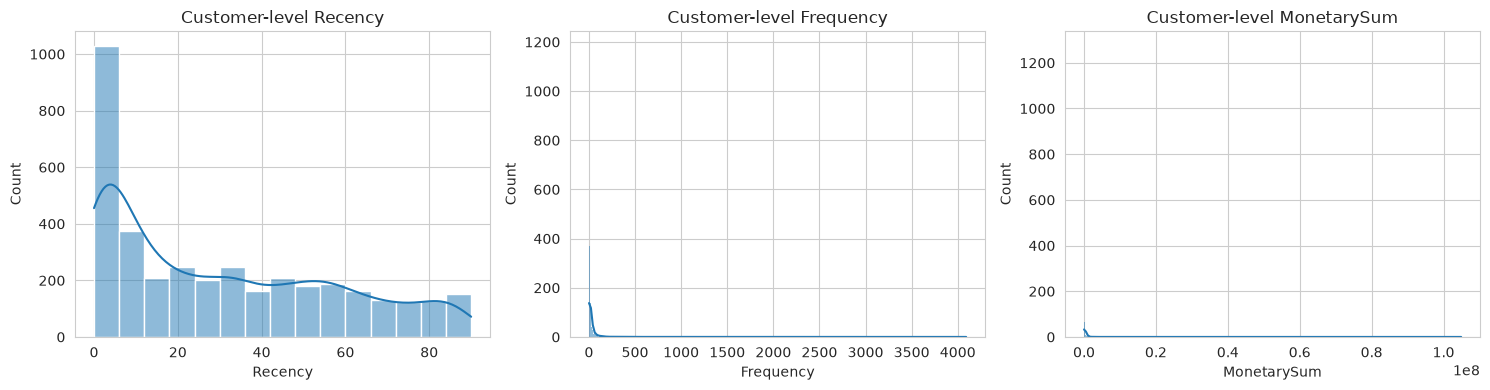

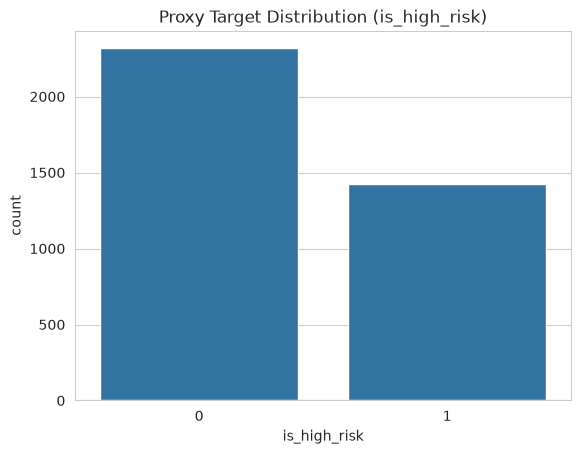

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "MonetarySum"]):
    sns.histplot(customer_df[col], kde=True, ax=ax)
    ax.set_title(f"Customer-level {col}")
plt.tight_layout()
plt.show()

sns.countplot(data=customer_df, x="is_high_risk")
plt.title("Proxy Target Distribution (is_high_risk)")
plt.show()

## Top Insights

The dataset holds **95,662 transactions across 16 columns for 3,742 customers**, with **no missing values** in any column.

1. **Extreme right skew in transaction amounts.** `Value` has a skewness of **51.3** — the median is 1,000 but the maximum is 9,880,000. Raw amounts would let a handful of transactions dominate any distance-based model, so the pipeline scales features with `StandardScaler` and models customers through RFM aggregates rather than individual transactions.

2. **Severe customer concentration.** The **top 1% of customers account for 55.8% of total transaction value**. This long tail is what makes RFM segmentation viable: engagement, not demographics, is the signal that separates customers, and it justifies the K-Means proxy target.

3. **`Amount` and `Value` are near-collinear (r = 0.990), and two columns are constant.** `Value` is the absolute magnitude of `Amount`, so only `Value` feeds the monetary aggregates. `CountryCode` and `CurrencyCode` have a single distinct value each and carry zero information, so they are excluded from the feature set.

4. **`FraudResult` cannot serve as the target.** Only **0.202%** of transactions are flagged as fraud, and fraud is a different event from credit default anyway. Combined with the absence of any repayment column, this confirms that a proxy label is unavoidable — hence `is_high_risk` from RFM clustering.

5. **Categorical features are heavily imbalanced.** `financial_services` (47.5%) and `airtime` (47.1%) cover **94.5%** of `ProductCategory`, and two channels cover 98.4% of `ChannelId`. Rare categories will appear at inference that were never seen in training, so `OneHotEncoder` is configured with `handle_unknown="ignore"`.

6. **Nearly 40% of transactions have a negative `Amount`**, indicating refunds or reversals. Summing signed amounts would understate customer activity, so monetary aggregates use `Value` (the unsigned magnitude).

### Cluster interpretation

K-Means on scaled RFM produces one clearly disengaged segment, which becomes the high-risk proxy:

| Cluster | Customers | Avg recency (days) | Avg frequency | Avg monetary | Label |
| --- | --- | --- | --- | --- | --- |
| **0** | 1,426 (38%) | **60.9** | **7.7** | **89,738** | **High risk (1)** |
| 1 | 2,312 (62%) | 11.7 | 34.7 | 224,757 | Low risk (0) |
| 2 | 4 (0.1%) | 22.3 | 1,104.5 | 74,876,587 | Low risk (0) |

Cluster 0 is dormant on every dimension at once — roughly **5x more days since last activity, 4.5x fewer transactions, and 2.5x lower spend** than cluster 1 — which is exactly the "disengaged" profile the proxy is meant to capture. Cluster 2 is a handful of high-volume outliers that K-Means isolates rather than letting them distort the other centroids.